# Can we use Sentiment Analysis to Predict Stock Prices?


In [1]:
#!nvidia-smi

In [2]:
#!pip install yfinance 
#!pip install tqdm

In [3]:
# As we Scrape all the data with snscrape from twitter I commented this part
#!pip install snscrape 

In [4]:
#!pip install transformers 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import plotly.graph_objects as go
from tqdm import tqdm

import warnings
warnings.filterwarnings('ignore')

## Example Pulling Microsoft Stock

In [6]:
msft = yf.Ticker("MSFT")

In [7]:
msft_hist = msft.history(period="max")

In [8]:
msft_hist.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1986-03-13 00:00:00-05:00,0.053745,0.061649,0.053745,0.059014,1031788800,0.0,0.0
1986-03-14 00:00:00-05:00,0.059014,0.062176,0.059014,0.061122,308160000,0.0,0.0
1986-03-17 00:00:00-05:00,0.061122,0.062703,0.061122,0.062176,133171200,0.0,0.0
1986-03-18 00:00:00-05:00,0.062176,0.062703,0.060068,0.060595,67766400,0.0,0.0
1986-03-19 00:00:00-05:00,0.060595,0.061122,0.059014,0.059541,47894400,0.0,0.0


In [9]:
msft_hist.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10230 entries, 1986-03-13 00:00:00-05:00 to 2026-10-20 00:00:00-04:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          10230 non-null  float64
 1   High          10230 non-null  float64
 2   Low           10230 non-null  float64
 3   Close         10230 non-null  float64
 4   Volume        10230 non-null  int64  
 5   Dividends     10230 non-null  float64
 6   Stock Splits  10230 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 639.4 KB


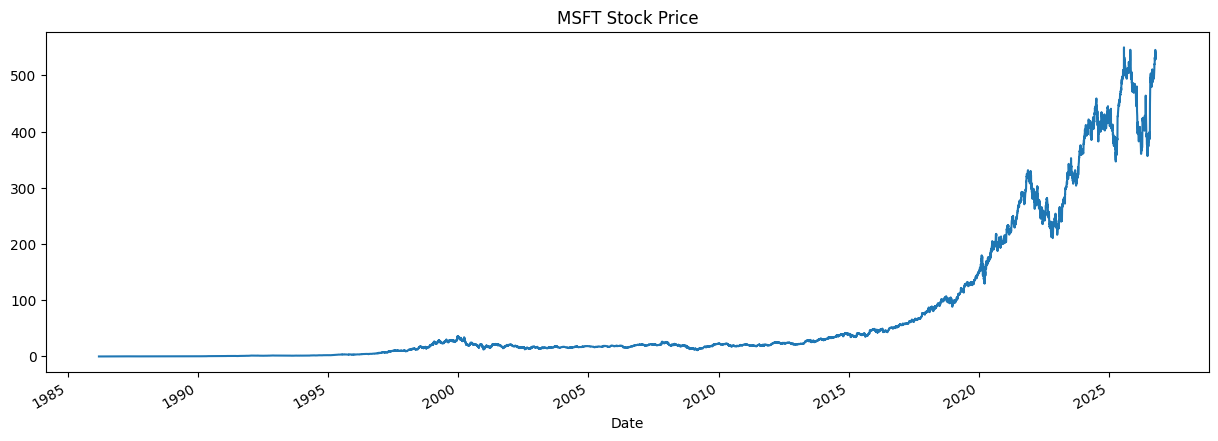

In [11]:
msft_hist["Open"].plot(figsize=(15, 5), title="MSFT Stock Price")
plt.show()

In [12]:
stocks = [
    "NVDA",
    "PINS",
    "TSLA",
    "SHOP",
    "O",
    "NKE",
    "GOOG",
    "META",
    "MSFT",
    "AMZN",
    "ZM",
    "PFE",
    "MRNA",
    "SPOT",
    "TMUS",
]

In [13]:
hists = {}
for s in stocks:
    tkr = yf.Ticker(s)
    history = tkr.history(period="3y")
    hists[s] = history

In [14]:
len(hists)

15

# Plot the Stock Price

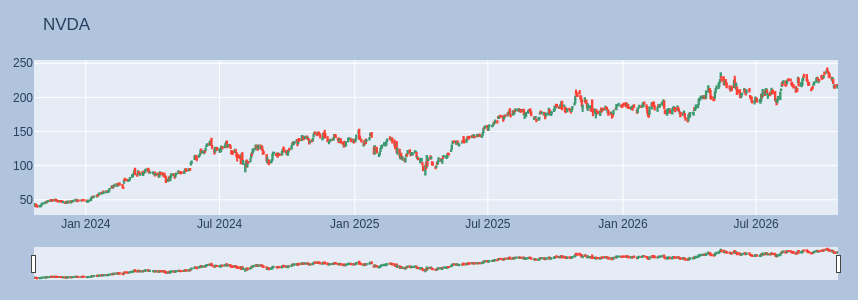

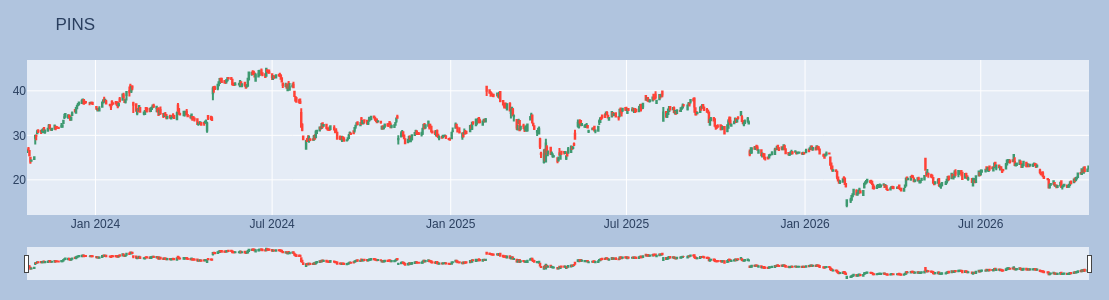

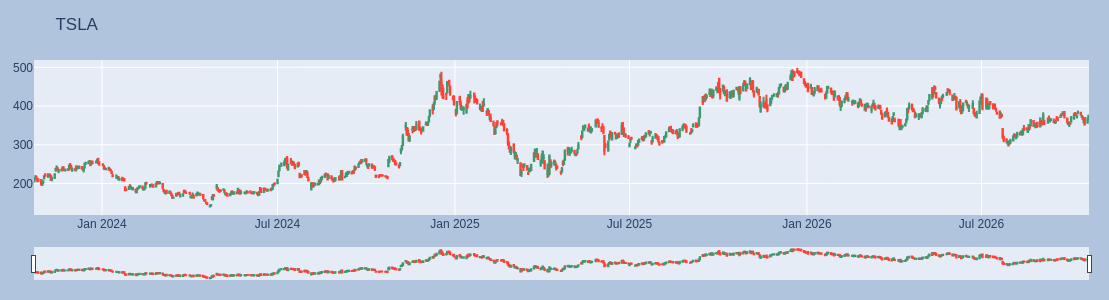

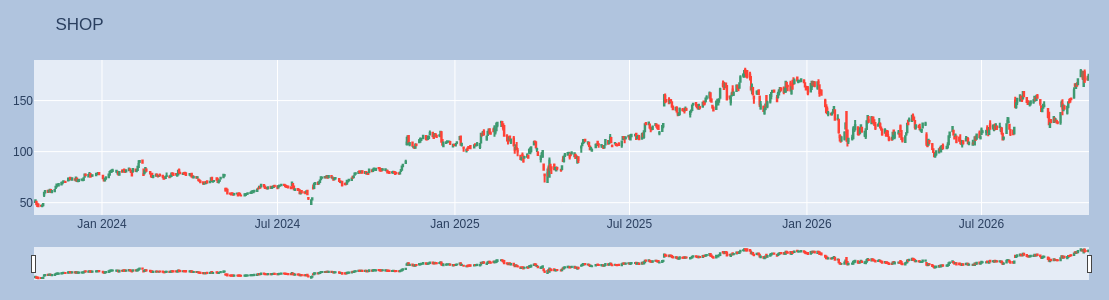

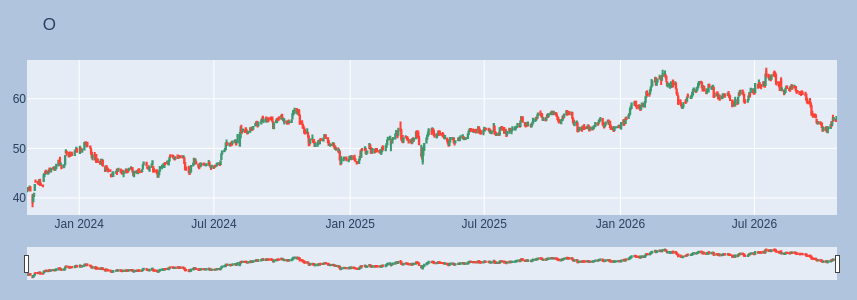

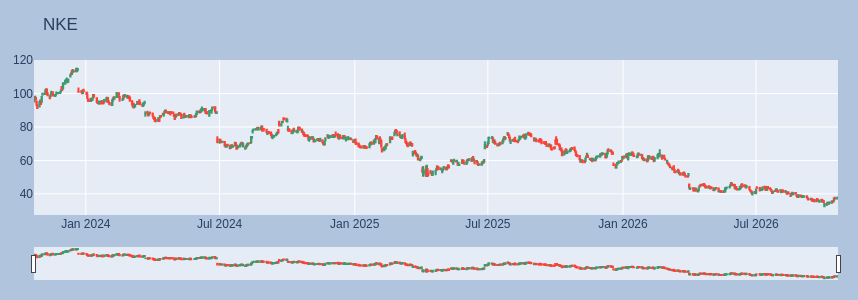

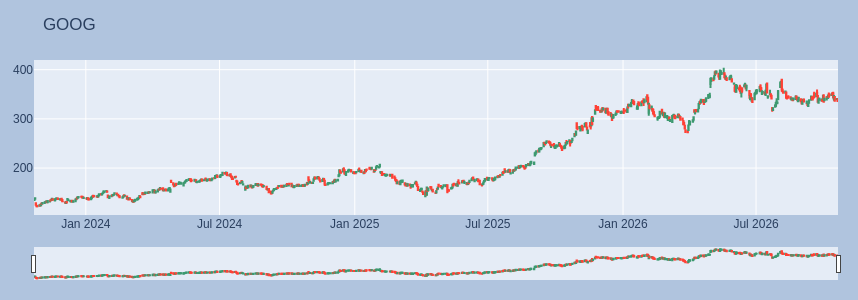

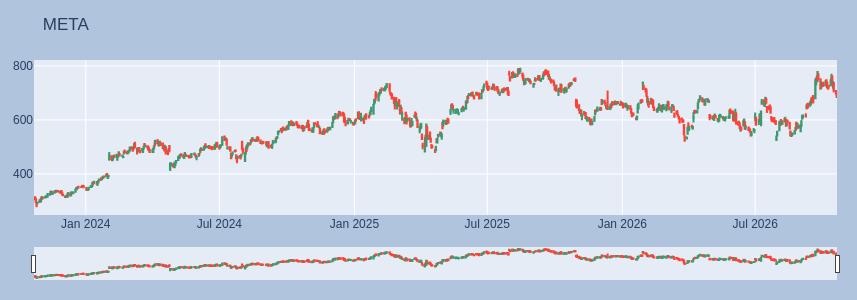

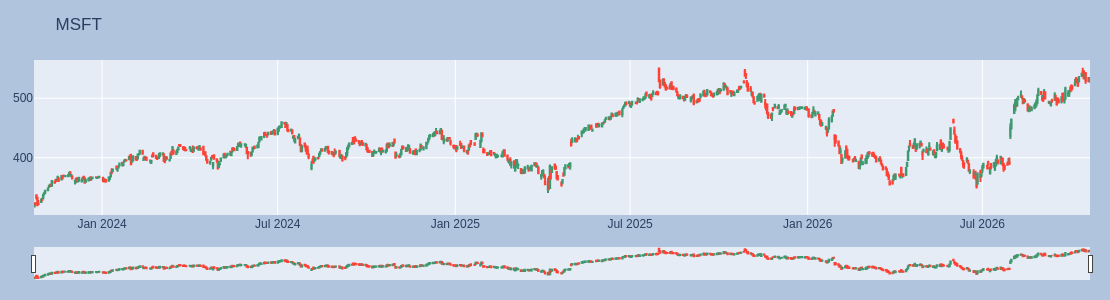

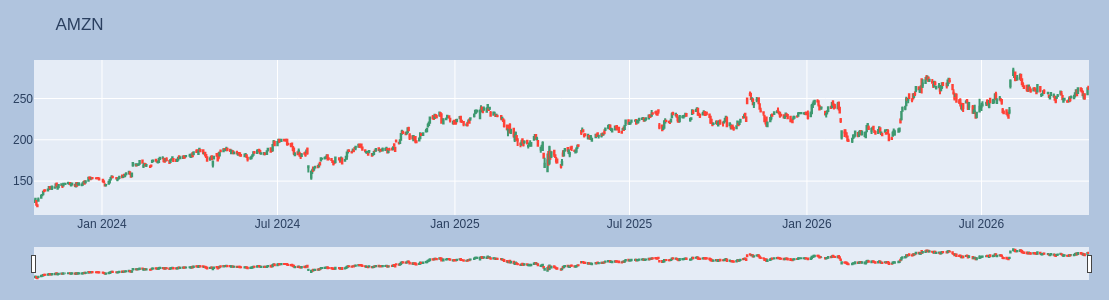

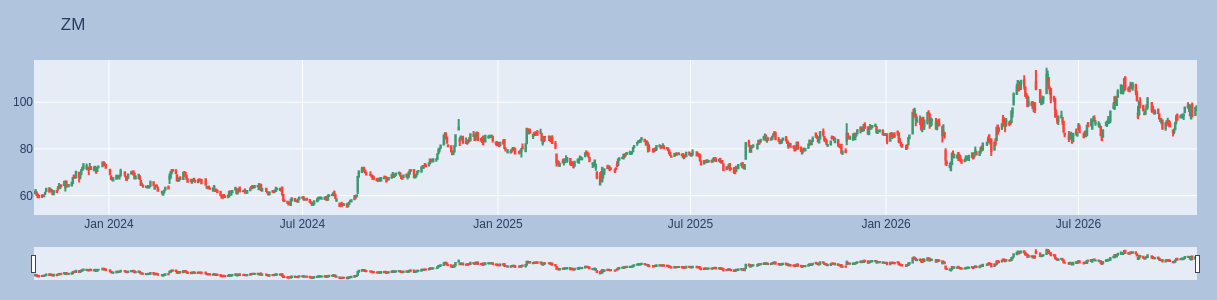

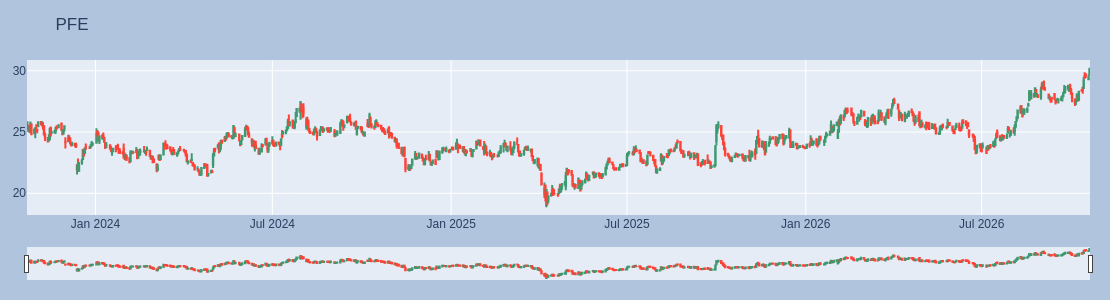

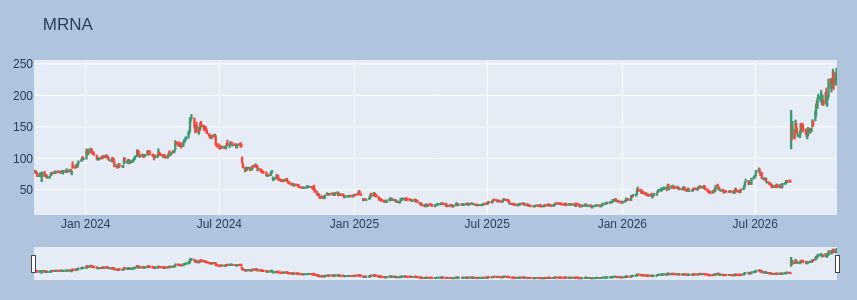

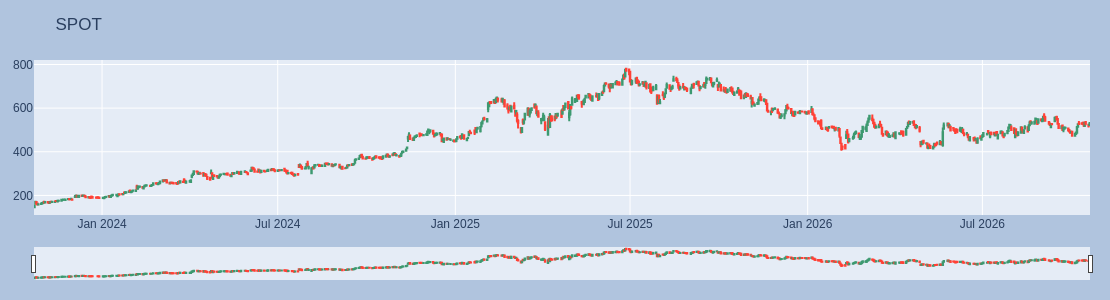

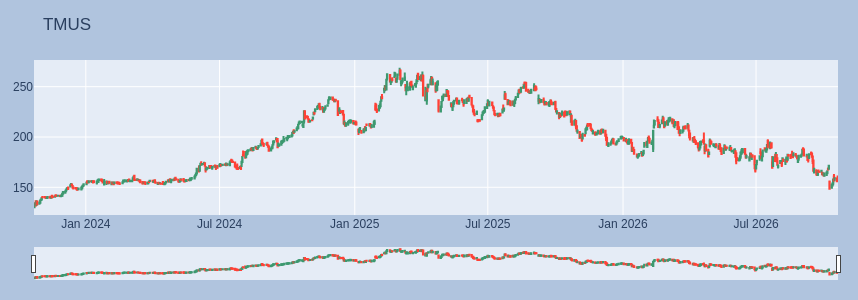

In [15]:
for stock in stocks:
    temp_df = hists[stock].copy()

    fig = go.Figure(
        data=[
            go.Candlestick(
                x=temp_df.index,
                open=temp_df["Open"],
                high=temp_df["High"],
                low=temp_df["Low"],
                close=temp_df["Close"],
            )
        ]
    )

    fig.update_layout(
        margin=dict(l=20, r=20, t=60, b=20),
        height=300,
        paper_bgcolor="LightSteelBlue",
        title=stock,
    )

    fig.show()

# Pull Tweets about each Stock

In [16]:
hists["NVDA"].index.min()

Timestamp('2023-10-23 00:00:00-0400', tz='America/New_York')

In [17]:
stock = "NVDA"

In [18]:
# Source code for scrape the tweets

# # importing libraries and packages
# import snscrape.modules.twitter as sntwitter
# from tqdm.notebook import tqdm

# # Creating list to append tweet data
# tweets_list = []
# # Using TwitterSearchScraper to scrape data and append tweets to list
# for i, tweet in tqdm(
#     enumerate(
#         sntwitter.TwitterSearchScraper(
#             f"${stock} since:2020-02-04 until:2023-05-02"
#         ).get_items()
#     ),
#     total=100_000,
# ):  # declare a username
#     if i > 100_000:  # number of tweets you want to scrape
#         break
#     tweets_list.append(
#         [tweet.date, tweet.id, tweet.content, tweet.user.username]
#     )  # declare the attributes to be returned
# # Creating a dataframe from the tweets list above
# tweet_df = pd.DataFrame(
#     tweets_list, columns=["Datetime", "Tweet Id", "Text", "Username"]
# )

In [19]:
tweet_df=pd.read_csv("Nvidia-Tweets.csv")

In [20]:
tweet_df

,Unnamed: 0,Datetime,Tweet Id,Text,Username
0,0,2023-02-06 10:07:17+00:00,1.622537e+18,$nvda Top analyst price target for next week ...,RyderJohnston6
1,1,2023-02-06 10:06:30+00:00,1.622537e+18,$nvda Top analyst price target for this week.🔗...,k_mebane
2,2,2023-02-06 10:06:08+00:00,1.622537e+18,$nvda Top analyst price target for next week.....,RonaldBevan2
3,3,2023-02-06 10:05:43+00:00,1.622537e+18,$NVDA Top analyst target price for next week🚀 ...,Eva077777
4,4,2023-02-06 10:03:49+00:00,1.622537e+18,$rsls rebound 🚨🚨🚀🚀🚀\n————\n\n$EDSA\n$KODK\n$DO...,MrBlackTrading
...,...,...,...,...,...
100842,99996,2022-11-21 14:32:00+00:00,1.594700e+18,Real-time trading alerts from our team of seas...,Vinesh00518
100843,99997,2022-11-21 14:32:00+00:00,1.594700e+18,50k+ members\nDo join=&gt;https://t.co/4zYWlhg...,bishnuvardhan
100844,99998,2022-11-21 14:32:00+00:00,1.594700e+18,Couple of stats and quotes for the week ahead....,RAJURAY98
100845,99999,2022-11-21 14:30:28+00:00,1.594700e+18,$NVDA Critical level $150! https://t.co/AdQoNa...,jakethestockguy


In [21]:
tweet_df.isnull().sum()

Unnamed: 0       0
Datetime       478
Tweet Id       846
Text           846
Username      1214
dtype: int64

In [22]:
tweet_df.dropna(inplace=True)

In [23]:
tweet_df.shape

(99633, 5)

In [24]:
# tweet_df.to_csv('Nvidia-Tweets.csv')

In [25]:
# tweet_df.to_parquet("Nvidia_tweets.parquet")

## Sentiment Analysis Prep

In [26]:
from transformers import pipeline

model = f"cardiffnlp/twitter-roberta-base-sentiment-latest"

sentiment_task = pipeline("sentiment-analysis", model=model)
sentiment_task("I love to code in python and it's amazing to use huggingface for sentiment analysis")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'label': 'positive', 'score': 0.9827125072479248}]

In [27]:
sent_results = {}
count = 0
for i, d in tqdm(tweet_df.iterrows(), total=len(tweet_df)):
    sent = sentiment_task(d["Text"])
    sent_results[d["Tweet Id"]] = sent
    count += 1
    if count == 60000:
        break

 60%|███████████████████████████████████████████████████████████████████████████████████▋                                                       | 59999/99633 [04:45<03:08, 210.10it/s]


In [28]:
sent_results

{1.62253740706014e+18: [{'label': 'positive', 'score': 0.6267979145050049}],
 1.6225372078474527e+18: [{'label': 'positive', 'score': 0.8709065914154053}],
 1.6225371169988608e+18: [{'label': 'positive', 'score': 0.6359902024269104}],
 1.622537012158042e+18: [{'label': 'positive', 'score': 0.8311949372291565}],
 1.6225365326565908e+18: [{'label': 'positive', 'score': 0.8050742745399475}],
 1.622535627408552e+18: [{'label': 'positive', 'score': 0.8929926753044128}],
 1.622535020060545e+18: [{'label': 'positive', 'score': 0.7525831460952759}],
 1.6225344991407882e+18: [{'label': 'positive', 'score': 0.6623905301094055}],
 1.6225344084641382e+18: [{'label': 'neutral', 'score': 0.8421576619148254}],
 1.6225327903729377e+18: [{'label': 'neutral', 'score': 0.5409578680992126}],
 1.622532481948975e+18: [{'label': 'positive', 'score': 0.587590217590332}],
 1.622529448829395e+18: [{'label': 'neutral', 'score': 0.7915419936180115}],
 1.622529447696941e+18: [{'label': 'neutral', 'score': 0.816664

In [29]:
sent_df = pd.DataFrame(sent_results).T
sent_df["label"] = sent_df[0].apply(lambda x: x["label"])
sent_df["score"] = sent_df[0].apply(lambda x: x["score"])
sent_df = sent_df.merge(
    tweet_df.set_index("Tweet Id"), left_index=True, right_index=True
)

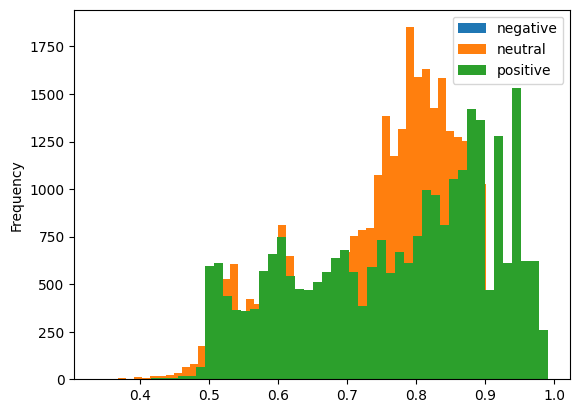

In [30]:
sent_df.groupby("label")["score"].plot(kind="hist", bins=50)
plt.legend()
plt.show()

In [31]:
sent_df.sample(10)

,0,label,score,Unnamed: 0,Datetime,Text,Username
1.606017e+18,"{'label': 'neutral', 'score': 0.6647815108299255}",neutral,0.664782,60193,2022-12-22 20:00:01+00:00,12/22 Signals Recap💰\n\nMissed our entry on $N...,HighStrikeInc
1.609250e+18,"{'label': 'positive', 'score': 0.8720184564590...",positive,0.872018,47594,2022-12-31 18:06:47+00:00,$nvda Top analyst price target for next week.....,RobertM53826291
1.615190e+18,"{'label': 'neutral', 'score': 0.8186148405075073}",neutral,0.818615,28577,2023-01-17 03:32:12+00:00,$KODK $DOW $GNUS $IDEX $BOXL $BABA $TSLA $TAOP...,vaikunt305
1.620644e+18,"{'label': 'neutral', 'score': 0.8039565682411194}",neutral,0.803957,6920,2023-02-01 04:45:10+00:00,TRADING STATS FROM today https://t.co/dqoVdzKw...,nappedonthebed
1.615818e+18,"{'label': 'positive', 'score': 0.5846226215362...",positive,0.584623,25749,2023-01-18 21:05:26+00:00,Just looked at the big options trades for tech...,Steve_382
1.608495e+18,"{'label': 'positive', 'score': 0.7743854522705...",positive,0.774385,50738,2022-12-29 16:06:36+00:00,$NVDA *Top analyst price target for the week....,stockbest001
1.613887e+18,"{'label': 'positive', 'score': 0.7494173049926...",positive,0.749417,31779,2023-01-13 13:12:57+00:00,Top Chatroom\nhttps://t.co/ZBTRgq0AN6\n\nJoin ...,Smith28301
1.618701e+18,"{'label': 'neutral', 'score': 0.8418622016906738}",neutral,0.841862,14276,2023-01-26 20:04:02+00:00,Bears vs Bulls today \n\n$CRM $SQ $SPY $TSLA $...,ArtofaPanda
1.620520e+18,"{'label': 'neutral', 'score': 0.5879871845245361}",neutral,0.587987,7475,2023-01-31 20:31:55+00:00,$APRN $1 🚀\n\nMcap:40Mil\n\nRev:$450Mil\n\nSI:...,StockSqueezeSpy
1.611128e+18,"{'label': 'positive', 'score': 0.879463255405426}",positive,0.879463,40985,2023-01-05 22:29:37+00:00,"“Most winning trading community, Get next winn...",dowjone620


In [48]:
sent_df["label"] = sent_df["label"].str.lower()

sent_df["score_"] = np.select(
    [
        sent_df["label"] == "negative",
        sent_df["label"] == "neutral",
        sent_df["label"] == "positive",
    ],
    [
        -sent_df["score"],
        0,
        sent_df["score"],
    ],
    default=np.nan,
)

<Axes: ylabel='Frequency'>

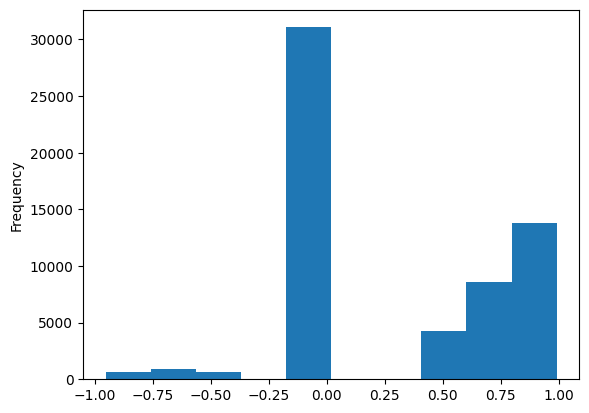

In [33]:
sent_df["score_"].plot(kind="hist", bins=10)

In [34]:
sent_df

,0,label,score,Unnamed: 0,Datetime,Text,Username,score_
1.622537e+18,"{'label': 'positive', 'score': 0.6267979145050...",positive,0.626798,0,2023-02-06 10:07:17+00:00,$nvda Top analyst price target for next week ...,RyderJohnston6,0.626798
1.622537e+18,"{'label': 'positive', 'score': 0.8709065914154...",positive,0.870907,1,2023-02-06 10:06:30+00:00,$nvda Top analyst price target for this week.🔗...,k_mebane,0.870907
1.622537e+18,"{'label': 'positive', 'score': 0.6359902024269...",positive,0.635990,2,2023-02-06 10:06:08+00:00,$nvda Top analyst price target for next week.....,RonaldBevan2,0.635990
1.622537e+18,"{'label': 'positive', 'score': 0.8311949372291...",positive,0.831195,3,2023-02-06 10:05:43+00:00,$NVDA Top analyst target price for next week🚀 ...,Eva077777,0.831195
1.622537e+18,"{'label': 'positive', 'score': 0.8050742745399...",positive,0.805074,4,2023-02-06 10:03:49+00:00,$rsls rebound 🚨🚨🚀🚀🚀\n————\n\n$EDSA\n$KODK\n$DO...,MrBlackTrading,0.805074
...,...,...,...,...,...,...,...,...
1.606012e+18,"{'label': 'neutral', 'score': 0.8076141476631165}",neutral,0.807614,60219,2022-12-22 19:41:26+00:00,$NVDA most active put option: 23-Dec-22 150.00...,MarketChmln,0.000000
1.606012e+18,"{'label': 'positive', 'score': 0.9768104553222...",positive,0.976810,60220,2022-12-22 19:41:23+00:00,+10% on the account today ✅\n\nfucking quality...,L3120L,0.976810
1.606012e+18,"{'label': 'positive', 'score': 0.639562726020813}",positive,0.639563,60222,2022-12-22 19:40:49+00:00,$NVDA Top analyst price target for next week\n...,Felicia51342059,0.639563
1.606012e+18,"{'label': 'neutral', 'score': 0.7782889008522034}",neutral,0.778289,60223,2022-12-22 19:40:20+00:00,"$NVDA Vlak hierna volgde een bulltrap, nu weg ...",CantillonRuurd,0.000000


In [35]:
sent_df['Datetime']= pd.to_datetime(sent_df['Datetime'])

In [36]:
sent_df["Date"] = sent_df["Datetime"].dt.date

In [37]:
sent_df["Date"]

1.622537e+18    2023-02-06
1.622537e+18    2023-02-06
1.622537e+18    2023-02-06
1.622537e+18    2023-02-06
1.622537e+18    2023-02-06
                   ...    
1.606012e+18    2022-12-22
1.606012e+18    2022-12-22
1.606012e+18    2022-12-22
1.606012e+18    2022-12-22
1.606012e+18    2022-12-22
Name: Date, Length: 60000, dtype: object

In [38]:
sent_daily = sent_df.groupby("Date")["score_"].mean()
sent_daily

Date
2022-12-22    0.208673
2022-12-23    0.316962
2022-12-24    0.332261
2022-12-25    0.339532
2022-12-26    0.358673
2022-12-27    0.244490
2022-12-28    0.258485
2022-12-29    0.286262
2022-12-30    0.318017
2022-12-31    0.342771
2023-01-01    0.379748
2023-01-02    0.375010
2023-01-03    0.265246
2023-01-04    0.307335
2023-01-05    0.298418
2023-01-06    0.311854
2023-01-07    0.347698
2023-01-08    0.336939
2023-01-09    0.316447
2023-01-10    0.321345
2023-01-11    0.301997
2023-01-12    0.318675
2023-01-13    0.311498
2023-01-14    0.419148
2023-01-15    0.436917
2023-01-16    0.425697
2023-01-17    0.349216
2023-01-18    0.349242
2023-01-19    0.330430
2023-01-20    0.340147
2023-01-21    0.366110
2023-01-22    0.415938
2023-01-23    0.296308
2023-01-24    0.293473
2023-01-25    0.286691
2023-01-26    0.264996
2023-01-27    0.289470
2023-01-28    0.365798
2023-01-29    0.371882
2023-01-30    0.292376
2023-01-31    0.325910
2023-02-01    0.316268
2023-02-02    0.344259
2023-0

In [39]:
Nvidia_df = hists["NVDA"].copy()
Nvidia_df = Nvidia_df.reset_index()
Nvidia_df["Date"] = Nvidia_df["Date"].dt.date
Nvidia_df = Nvidia_df.set_index("Date")
Nvidia_df

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-10-23,41.106239,43.119228,40.823084,42.847038,478530000,0.0,0.0
2023-10-24,42.948725,43.566877,42.563876,43.532978,401463000,0.0,0.0
2023-10-25,43.268773,43.520025,41.431262,41.654594,398379000,0.0,0.0
2023-10-26,41.728375,42.130175,39.761250,40.205921,541001000,0.0,0.0
2023-10-27,41.007527,41.083301,39.895846,40.379402,416784000,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-14,225.529999,226.000000,219.639999,221.300003,118730100,0.0,0.0
2026-10-15,215.300003,218.470001,212.850006,217.229996,127087900,0.0,0.0
2026-10-16,216.559998,218.679993,213.320007,214.130005,121252500,0.0,0.0


In [40]:
Nvidia_df = yf.Ticker("NVDA").history(
    start="2022-12-22",
    end="2023-02-07"
)

Nvidia_df.index = pd.to_datetime(Nvidia_df.index).date
Nvidia_df.index.name = "Date"

print(Nvidia_df.head())
print(Nvidia_df.index.min(), Nvidia_df.index.max())

                 Open       High        Low      Close     Volume  Dividends  \
Date                                                                           
2022-12-22  16.040371  16.084225  14.832410  15.287887  565045000        0.0   
2022-12-23  15.145361  15.287884  14.833404  15.155328  349326000        0.0   
2022-12-27  15.023769  15.049683  14.009161  14.073945  464902000        0.0   
2022-12-28  13.880592  14.214476  13.837735  13.989229  351066000        0.0   
2022-12-29  14.354008  14.634071  14.179591  14.554338  354923000        0.0   

            Stock Splits  
Date                      
2022-12-22           0.0  
2022-12-23           0.0  
2022-12-27           0.0  
2022-12-28           0.0  
2022-12-29           0.0  
2022-12-22 2023-02-06


In [41]:
print("Tweet dates:")
print(sent_daily.index.min(), sent_daily.index.max())

print("\nStock dates:")
print(Nvidia_df.index.min(), Nvidia_df.index.max())

Tweet dates:
2022-12-22 2023-02-06

Stock dates:
2022-12-22 2023-02-06


In [42]:
sent_and_stock = sent_daily.to_frame("sentiment").merge(
    Nvidia_df,
    left_index=True,
    right_index=True,
    how="inner"
)

print(sent_and_stock.shape)
print(sent_and_stock.head())

(30, 8)
            sentiment       Open       High        Low      Close     Volume  \
Date                                                                           
2022-12-22   0.208673  16.040371  16.084225  14.832410  15.287887  565045000   
2022-12-23   0.316962  15.145361  15.287884  14.833404  15.155328  349326000   
2022-12-27   0.244490  15.023769  15.049683  14.009161  14.073945  464902000   
2022-12-28   0.258485  13.880592  14.214476  13.837735  13.989229  351066000   
2022-12-29   0.286262  14.354008  14.634071  14.179591  14.554338  354923000   

            Dividends  Stock Splits  
Date                                 
2022-12-22        0.0           0.0  
2022-12-23        0.0           0.0  
2022-12-27        0.0           0.0  
2022-12-28        0.0           0.0  
2022-12-29        0.0           0.0  


In [43]:
sent_and_stock = sent_daily.to_frame("sentiment").merge(
    Nvidia_df,
    left_index=True,
    right_index=True
)

sent_and_stock

,sentiment,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2022-12-22,0.208673,16.040371,16.084225,14.832410,15.287887,565045000,0.0,0.0
2022-12-23,0.316962,15.145361,15.287884,14.833404,15.155328,349326000,0.0,0.0
2022-12-27,0.244490,15.023769,15.049683,14.009161,14.073945,464902000,0.0,0.0
2022-12-28,0.258485,13.880592,14.214476,13.837735,13.989229,351066000,0.0,0.0
2022-12-29,0.286262,14.354008,14.634071,14.179591,14.554338,354923000,0.0,0.0
2022-12-30,0.318017,14.286234,14.580251,14.185571,14.565302,310490000,0.0,0.0
2023-01-03,0.265246,14.801513,14.946030,14.049029,14.267299,401277000,0.0,0.0
2023-01-04,0.307335,14.518459,14.803506,14.193545,14.699852,431324000,0.0,0.0
2023-01-05,0.298418,14.442712,14.515469,14.100855,14.217465,389168000,0.0,0.0


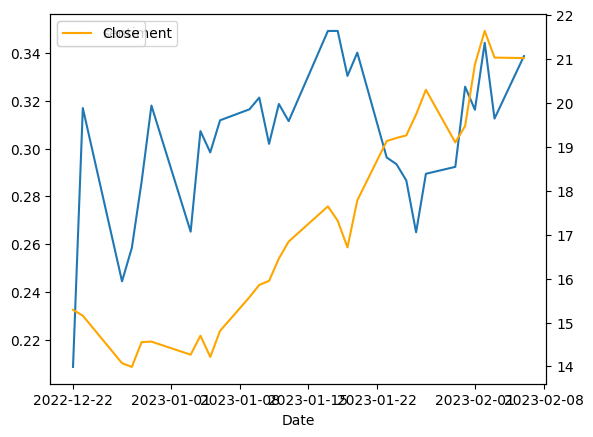

In [44]:
ax = sent_and_stock["sentiment"].plot(legend="Sentiment")
ax2 = ax.twinx()
sent_and_stock["Close"].plot(ax=ax2, color="orange", legend="Closing Price")
plt.show()

In [5]:
# fig, ax1 = plt.subplots(figsize=(15, 6))

# ax1.plot(
#     sent_and_stock.index,
#     sent_and_stock["sentiment"],
#     label="Daily Sentiment"
# )
# ax1.set_ylabel("Sentiment")
# ax1.set_xlabel("Date")

# ax2 = ax1.twinx()

# ax2.plot(
#     sent_and_stock.index,
#     sent_and_stock["Close"],
#     color="orange",
#     label="NVDA Closing Price"
# )
# ax2.set_ylabel("Closing Price ($)")

In [45]:
hists["NVDA"]

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-10-23 00:00:00-04:00,41.106239,43.119228,40.823084,42.847038,478530000,0.0,0.0
2023-10-24 00:00:00-04:00,42.948725,43.566877,42.563876,43.532978,401463000,0.0,0.0
2023-10-25 00:00:00-04:00,43.268773,43.520025,41.431262,41.654594,398379000,0.0,0.0
2023-10-26 00:00:00-04:00,41.728375,42.130175,39.761250,40.205921,541001000,0.0,0.0
2023-10-27 00:00:00-04:00,41.007527,41.083301,39.895846,40.379402,416784000,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-14 00:00:00-04:00,225.529999,226.000000,219.639999,221.300003,118730100,0.0,0.0
2026-10-15 00:00:00-04:00,215.300003,218.470001,212.850006,217.229996,127087900,0.0,0.0
2026-10-16 00:00:00-04:00,216.559998,218.679993,213.320007,214.130005,121252500,0.0,0.0


<Axes: xlabel='Date'>

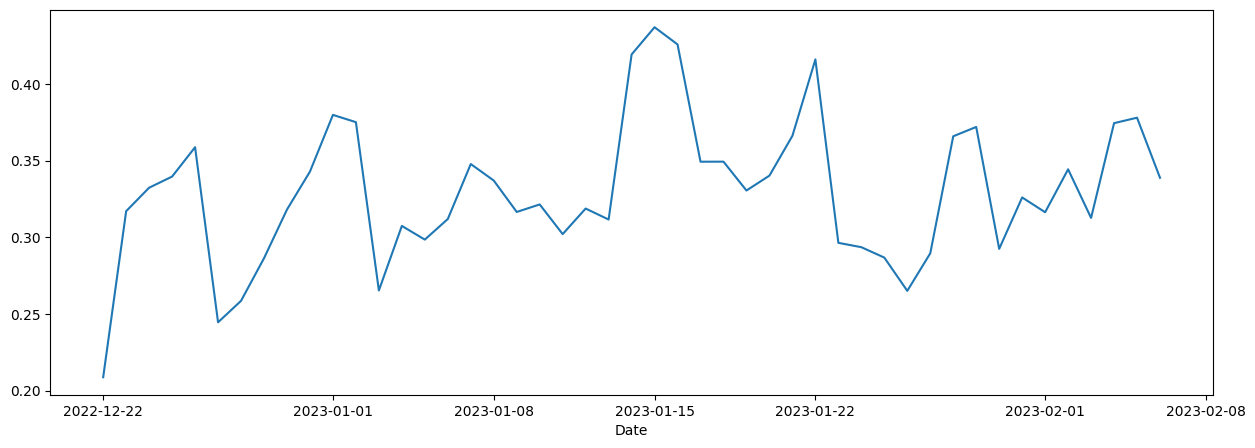

In [46]:
sent_df.groupby("Date")["score_"].mean().plot(figsize=(15,5))